# Treasury Market Basket — Similarity, Distance & Clustering

**Purpose.** Reframe treasury-service basket analysis as *unsupervised structure
discovery* instead of rule mining. Support/confidence/lift rules need a support
threshold and a minimum basket count to say anything; similarity and clustering
need neither. That makes this lens a useful cross-check — and, here, a useful
way to *expose* that there is almost nothing to discover.

**Data source.** `PL_DATA_STUDIO.DERIVED.CORE_TREASURY_ACCOUNTS_MONTHLY`,
pinned to `VERSION_PARTITION = '2.5'` and `DATE_PARTITION = '2026-08-31'`
(9 relationships x 11 treasury services). Both partition columns are always
pinned; an unpinned query mixes versions. Loaded via `mba_common.load_snapshot`.

---

## Degeneracy warning — read before any figure below

This snapshot is **degenerate**. Per `GROUND_TRUTH.md`:

- **9 of 11 services appear in every one of the 9 baskets.** Their binary
  column vectors are *bit-for-bit identical*.
- Therefore **any dendrogram structure among those 9 services is an arbitrary
  tie-breaking artifact of the linkage algorithm, not a discovered grouping.**
  Every merge inside that block occurs at height **exactly 0**; the nesting
  order reflects input column order and SciPy's tie-handling, not the data.
  (Both linkage methods below happen to resolve the ties the same way — that is
  shared tie-breaking, not corroboration.)
- The **only** genuine structure in the data is:
  1. the perfect `Incoming Foreign` <-> `Outgoing Foreign` couple (co-occur 8/8), and
  2. the single outlier basket `OBX Integrated & Co.`, which lacks both of them.
- Lift takes only two values across the whole dataset: `1.0` and `1.125`.
- No pair can reach significance at n = 9.

Nothing below should be read as a service-affinity narrative or a customer
segmentation. We name no segments and invent no affinities.

---

## Similarity measures compared

For a pair of items let `a` = baskets containing both, `b` = first only,
`c` = second only, `d` = neither, with `n = a+b+c+d`.

| Measure | Formula | Sensitivity to universal items |
|---|---|---|
| **Jaccard** | `a / (a+b+c)` | **Badly inflated.** Ignores `d`, so two universal items give `a=n, b=c=0` -> exactly 1.0. All 36 universal pairs tie at 1.0. |
| **Cosine** | `a / sqrt((a+b)(a+c))` | **Badly inflated**, -> 1.0 for universal pairs. On binary data this *is* Ochiai; we compute both to show they are numerically identical. |
| **Ochiai** | `a / sqrt((a+b)(a+c))` | Identical to binary cosine — demonstrated numerically below, so one of the two is redundant. |
| **Dice (F1)** | `2a / (2a+b+c)` | **Badly inflated** -> 1.0. Monotone in Jaccard, so it adds no ordering information, only rescaling. |
| **Sokal-Michener** (simple matching) | `(a+d) / n` | **Inflated for a different reason.** Credits joint *absence*. Universal pairs still score 1.0 via `a=n`, and co-rare items would score high too — rarely what a basket analyst means. |
| **phi / Matthews (MCC)** | `(ad - bc) / sqrt((a+b)(c+d)(a+c)(b+d))` | **Correctly refuses to answer.** A universal item has zero variance, so `(c+d)=0` and the denominator is 0 — phi is **undefined**. We set it explicitly to `0.0` ("no evidence of association") rather than emit `NaN`/`RuntimeWarning`. This is the honest measure here. |

The practical point: **Jaccard, cosine, Ochiai and Dice all report "perfect
similarity" for pairs that carry zero information**, because a variable that
never varies cannot covary. phi is the only one of the six that encodes that
fact. Watch for exactly that disagreement in the heatmaps.

## Import bootstrap

In [1]:
import sys
from pathlib import Path

try:
    import mba_common
except ModuleNotFoundError:
    _cands = [Path.cwd(),
              Path.cwd() / "investigations" / "treasury_mba",
              Path("/tmp"), Path("/home/udf/sandbox"), Path("/usr/lib/python_udf")]
    for _k in ("__vsc_ipynb_file__", "__file__"):
        try:
            _cands.insert(0, Path(globals()[_k]).resolve().parent)
        except Exception:
            pass
    for _p in _cands:
        if (_p / "mba_common.py").exists() and str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
    try:
        import mba_common
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "mba_common.py not found. Upload mba_common.py alongside this "
            "notebook (same stage / directory) and re-run this cell. Searched: "
            f"{[str(p) for p in _cands]}"
        ) from exc

print("mba_common loaded from", mba_common.__file__)

mba_common loaded from /Users/jeisenman/ra/qtwo_bench/investigations/treasury_mba/mba_common.py


## Parameters

In [2]:
# ------------------------------- PARAMETERS -------------------------------
VERSION_PARTITION = "2.5"                      # pinned snapshot version
DATE_PARTITION    = "2026-08-31"               # pinned snapshot date
LINKAGE_METHODS   = ("average", "complete")    # >= 2, compared side by side
ITEM_GRAIN        = "TREASURY_SERVICE_NAME"    # vs TREASURY_SERVICE_GROUP_NAME
CONNECTION_NAME   = "default"
# --------------------------------------------------------------------------

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 170)

print(f"grain    = {ITEM_GRAIN}")
print(f"linkages = {LINKAGE_METHODS}")
print(f"snapshot = {VERSION_PARTITION} / {DATE_PARTITION}")

grain    = TREASURY_SERVICE_NAME
linkages = ('average', 'complete')
snapshot = 2.5 / 2026-08-31


## Load the pinned snapshot and build the incidence matrix

`ITEM_GRAIN` is set to `TREASURY_SERVICE_NAME` deliberately. At the
`TREASURY_SERVICE_GROUP_NAME` grain there are only 3 groups and **all 3 appear
in all 9 baskets** — every similarity measure would be a constant matrix and
there would be literally nothing to cluster. The service grain retains exactly
one bit of variation (the two Foreign services), which is the most this data
offers.

In [3]:
snap = mba_common.load_snapshot(
    version_partition=VERSION_PARTITION,
    date_partition=DATE_PARTITION,
    connection_name=CONNECTION_NAME,
)
M = snap.basket_matrix(ITEM_GRAIN)          # baskets x items, boolean

_names = (snap.rows[[mba_common.BASKET_KEY, "RELATIONSHIP_NAME"]]
          .drop_duplicates()
          .set_index(mba_common.BASKET_KEY)["RELATIONSHIP_NAME"])
basket_labels = [str(_names.get(b, b))[:28] or str(b)[:8] for b in M.index]

print(f"baskets = {snap.n_baskets}   items = {M.shape[1]}")
print(f"basket sizes (sorted) = {sorted(M.sum(axis=1).tolist())}")
mba_common.item_support(M).rename("support").to_frame()

baskets = 9   items = 11
basket sizes (sorted) = [9, 11, 11, 11, 11, 11, 11, 11, 11]


,support
TREASURY_SERVICE_NAME,
Checks Deposited,1.000000
Debits,1.000000
Incoming Domestic,1.000000
Items Deposited,1.000000
Monthly Servicing,1.000000
Outgoing Domestic,1.000000
Retail Item,1.000000
Wholesale Deposit,1.000000
Wholesale Item,1.000000


## Degeneracy report (from `mba_common`)

In [4]:
rep = mba_common.degeneracy_report(M)

print(f"n_baskets             : {rep['n_baskets']}")
print(f"n_items               : {rep['n_items']}")
print(f"distinct basket sigs  : {rep['distinct_baskets']}   <- 9 rows collapse to this many")
print(f"distinct lift values  : {rep['distinct_lift_values']}")
print(f"is_degenerate         : {rep['is_degenerate']}")
print(f"universal items ({len(rep['universal_items'])}):")
for u in rep["universal_items"]:
    print("    -", u)

UNIVERSAL = list(rep["universal_items"])
VARYING = [c for c in M.columns if c not in UNIVERSAL]
print("\nvarying items:", VARYING)
print(f"\n==> {len(UNIVERSAL)} of {rep['n_items']} item columns are constant-TRUE and are")
print("    therefore mutually indistinguishable. Clustering cannot separate them;")
print("    any tree drawn among them is tie-breaking, not structure.")

n_baskets             : 9
n_items               : 11
distinct basket sigs  : 2   <- 9 rows collapse to this many
distinct lift values  : [1.0, 1.125]
is_degenerate         : False
universal items (9):
    - Checks Deposited
    - Debits
    - Incoming Domestic
    - Items Deposited
    - Monthly Servicing
    - Outgoing Domestic
    - Retail Item
    - Wholesale Deposit
    - Wholesale Item

varying items: ['Incoming Foreign', 'Outgoing Foreign']

==> 9 of 11 item columns are constant-TRUE and are
    therefore mutually indistinguishable. Clustering cannot separate them;
    any tree drawn among them is tie-breaking, not structure.


## Six similarity measures

All six come from the same `2x2` co-occurrence counts in one vectorised pass.
phi's zero-variance case is caught **explicitly** — no `errstate` suppression
and no `NaN` propagation: where the denominator vanishes we record `0.0` and
separately keep a boolean *phi-undefined* mask so the fact is auditable rather
than hidden.

In [5]:
V = M.to_numpy(dtype=float)
items = list(M.columns)
n_b, n_i = V.shape

A  = V.T @ V                      # both present
B  = V.T @ (1 - V)                # i present, j absent
Cc = (1 - V).T @ V                # i absent, j present
D  = (1 - V).T @ (1 - V)          # neither


def _safe(num, den):
    """Elementwise divide, returning 0.0 wherever the denominator vanishes."""
    out = np.zeros_like(num, dtype=float)
    ok = den > 0
    out[ok] = num[ok] / den[ok]
    return out


phi_den_sq = (A + B) * (Cc + D) * (A + Cc) * (B + D)
PHI_UNDEFINED = phi_den_sq <= 0          # zero-variance pairs: explicit mask

SIM = {
    "Jaccard":        _safe(A, A + B + Cc),
    "Cosine":         _safe(A, np.sqrt((A + B) * (A + Cc))),
    "Ochiai":         _safe(A, np.sqrt((A + B) * (A + Cc))),
    "Dice":           _safe(2 * A, 2 * A + B + Cc),
    "Sokal-Michener": (A + D) / n_b,
    "phi / MCC":      _safe(A * D - B * Cc, np.sqrt(np.maximum(phi_den_sq, 0.0))),
}
SIM = {k: pd.DataFrame(v, index=items, columns=items) for k, v in SIM.items()}

n_undef = int((PHI_UNDEFINED.sum() - np.trace(PHI_UNDEFINED)) // 2)
print(f"phi undefined (zero variance) for {n_undef} of {n_i * (n_i - 1) // 2} "
      "off-diagonal pairs -> set explicitly to 0.0")
print("Cosine == Ochiai elementwise:", bool(np.allclose(SIM["Cosine"], SIM["Ochiai"])))
assert not any(df.isna().to_numpy().any() for df in SIM.values()), "NaN leaked into SIM"

phi undefined (zero variance) for 54 of 55 off-diagonal pairs -> set explicitly to 0.0
Cosine == Ochiai elementwise: True


### Where the measures disagree

In [6]:
rows = []
cols = ["Jaccard", "Cosine", "Dice", "Sokal-Michener", "phi / MCC"]
for i, j in itertools.combinations(range(n_i), 2):
    r = {"item_a": items[i], "item_b": items[j],
         "a": int(A[i, j]), "b": int(B[i, j]),
         "c": int(Cc[i, j]), "d": int(D[i, j]),
         "phi_undef": bool(PHI_UNDEFINED[i, j])}
    for name in cols:
        r[name] = round(float(SIM[name].iloc[i, j]), 4)
    rows.append(r)
pairs = pd.DataFrame(rows)
pairs["spread"] = pairs[cols].max(axis=1) - pairs[cols].min(axis=1)

print("Distinct off-diagonal value sets per measure:")
for name, df in SIM.items():
    vals = sorted({round(float(df.iloc[i, j]), 4)
                   for i, j in itertools.combinations(range(n_i), 2)})
    print(f"  {name:<16} {vals}")

print("\nThe 10 pairs where the measures disagree most:")
pairs.sort_values("spread", ascending=False).head(10).reset_index(drop=True)

Distinct off-diagonal value sets per measure:
  Jaccard          [0.8889, 1.0]
  Cosine           [0.9428, 1.0]
  Ochiai           [0.9428, 1.0]
  Dice             [0.9412, 1.0]
  Sokal-Michener   [0.8889, 1.0]
  phi / MCC        [0.0, 1.0]

The 10 pairs where the measures disagree most:


,item_a,item_b,a,b,c,d,phi_undef,Jaccard,Cosine,Dice,Sokal-Michener,phi / MCC,spread
0,Checks Deposited,Debits,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
1,Items Deposited,Wholesale Item,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
2,Incoming Domestic,Retail Item,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
3,Incoming Domestic,Wholesale Deposit,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
4,Incoming Domestic,Wholesale Item,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
5,Checks Deposited,Incoming Domestic,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
6,Items Deposited,Monthly Servicing,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
7,Items Deposited,Outgoing Domestic,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
8,Items Deposited,Retail Item,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0
9,Items Deposited,Wholesale Deposit,9,0,0,0,True,1.0,1.0,1.0,1.0,0.0,1.0


**Read this table carefully — it is the central result of the notebook.**

- Every pair drawn from the 9 universal services scores
  **Jaccard = Cosine = Dice = Sokal-Michener = 1.000** while
  **phi = 0.000 (undefined, zero variance)**. A spread of 1.0 between measures
  on the *same pair* is the signature of "these numbers describe the sampling
  frame, not the customers."
- `Incoming Foreign` <-> `Outgoing Foreign` is the one pair where the agreement
  is *earned*: `a=8, b=c=0, d=1`, so Jaccard = 1.0 **and** phi = 1.0. It is the
  only pair with a defined, non-zero phi.
- A universal service against a Foreign service scores Jaccard ~ 0.889 — i.e.
  *lower* than the information-free pairs. The Jaccard ranking is therefore
  actively misleading on this data.

## Figure 1 — similarity heatmaps on a shared colour scale

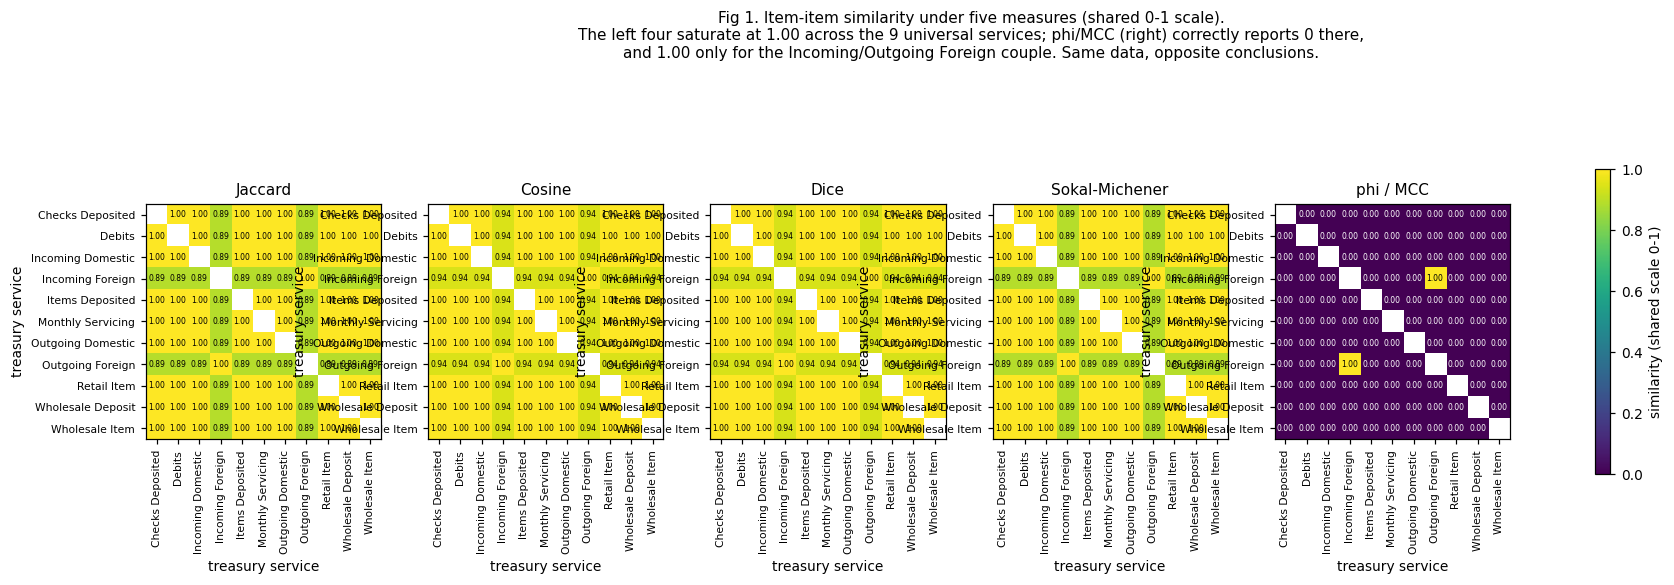

In [7]:
show = ["Jaccard", "Cosine", "Dice", "Sokal-Michener", "phi / MCC"]
fig, axes = plt.subplots(1, len(show), figsize=(4.0 * len(show), 5.0))
short = [s if len(s) <= 18 else s[:17] + "." for s in items]

for ax, name in zip(axes, show):
    arr = SIM[name].to_numpy().copy()
    np.fill_diagonal(arr, np.nan)
    im = ax.imshow(arr, vmin=0.0, vmax=1.0, cmap="viridis")   # shared scale
    ax.set_xticks(range(n_i)); ax.set_yticks(range(n_i))
    ax.set_xticklabels(short, rotation=90, fontsize=7)
    ax.set_yticklabels(short, fontsize=7)
    ax.set_title(name)
    ax.set_xlabel("treasury service")
    ax.set_ylabel("treasury service")
    for i in range(n_i):
        for j in range(n_i):
            if i == j:
                continue
            v = arr[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.0,
                    color="white" if v < 0.6 else "black")

fig.colorbar(im, ax=axes, shrink=0.72, label="similarity (shared scale 0-1)")
fig.suptitle(
    "Fig 1. Item-item similarity under five measures (shared 0-1 scale).\n"
    "The left four saturate at 1.00 across the 9 universal services; phi/MCC "
    "(right) correctly reports 0 there,\nand 1.00 only for the Incoming/Outgoing "
    "Foreign couple. Same data, opposite conclusions.",
    fontsize=10, y=1.06)
plt.show()

## Hierarchical clustering of services

Distance = `1 - Jaccard`. The 9 universal services sit at **mutual distance
exactly 0** — a single zero-diameter block of ties.

> ### Do not interpret the tree among the universal services
> SciPy must emit a binary tree, so it will fabricate a nested order inside that
> zero-distance block. The order depends on column order and on the linkage
> rule, not on the data. The two panels below resolve those ties identically —
> that is *shared tie-breaking*, not agreement about structure, and the printed
> merge heights show why: every merge but one sits at height 0. The *only*
> merge height that carries information is the one separating the Foreign pair
> from everything else.

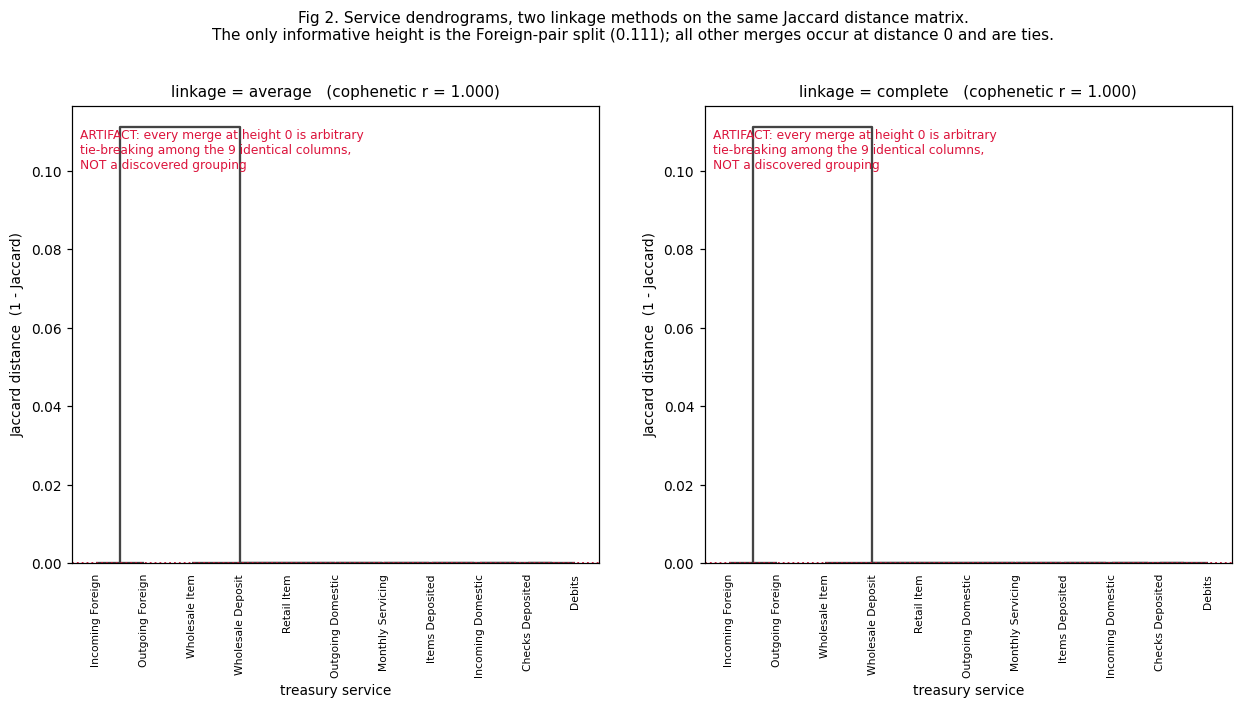

leaf order [ average]: ['Incoming Foreign', 'Outgoing Foreign', 'Wholesale Item', 'Wholesale Deposit', 'Retail Item', 'Outgoing Domestic', 'Monthly Servicing', 'Items Deposited', 'Incoming Domestic', 'Checks Deposited', 'Debits']
leaf order [complete]: ['Incoming Foreign', 'Outgoing Foreign', 'Wholesale Item', 'Wholesale Deposit', 'Retail Item', 'Outgoing Domestic', 'Monthly Servicing', 'Items Deposited', 'Incoming Domestic', 'Checks Deposited', 'Debits']

leaf orders identical across linkages: True
max distance between any two universal items: 0.0 (0.0 == indistinguishable)
merge heights (average linkage): [0.0, 0.1111]


In [8]:
Jd = (1.0 - SIM["Jaccard"]).to_numpy()
np.fill_diagonal(Jd, 0.0)
Jd = (Jd + Jd.T) / 2.0
condensed = squareform(Jd, checks=False)

fig, axes = plt.subplots(1, len(LINKAGE_METHODS),
                         figsize=(6.8 * len(LINKAGE_METHODS), 5.4))
axes = np.atleast_1d(axes)
orders, Zs = {}, {}
for ax, method in zip(axes, LINKAGE_METHODS):
    Z = hierarchy.linkage(condensed, method=method)
    Zs[method] = Z
    dn = hierarchy.dendrogram(Z, labels=items, ax=ax, leaf_rotation=90,
                              color_threshold=0.0, above_threshold_color="#444444")
    orders[method] = dn["ivl"]
    coph = hierarchy.cophenet(Z, condensed)[0]
    ax.set_title(f"linkage = {method}   (cophenetic r = {coph:.3f})")
    ax.set_xlabel("treasury service")
    ax.set_ylabel("Jaccard distance  (1 - Jaccard)")
    ax.tick_params(axis="x", labelsize=7)
    ax.axhline(0.0, color="crimson", lw=1.2, ls=":")
    ax.text(0.015, 0.95,
            "ARTIFACT: every merge at height 0 is arbitrary\n"
            "tie-breaking among the 9 identical columns,\n"
            "NOT a discovered grouping",
            transform=ax.transAxes, fontsize=8, color="crimson", va="top")

fig.suptitle("Fig 2. Service dendrograms, two linkage methods on the same Jaccard "
             "distance matrix.\nThe only informative height is the Foreign-pair "
             "split (0.111); all other merges occur at distance 0 and are ties.", fontsize=10, y=1.04)
plt.show()

for m in LINKAGE_METHODS:
    print(f"leaf order [{m:>8}]: {orders[m]}")
print(f"\nleaf orders identical across linkages: "
      f"{orders[LINKAGE_METHODS[0]] == orders[LINKAGE_METHODS[-1]]}")

ui = [items.index(u) for u in UNIVERSAL]
print("max distance between any two universal items:",
      float(np.max(Jd[np.ix_(ui, ui)])), "(0.0 == indistinguishable)")
print("merge heights (average linkage):",
      sorted({round(float(h), 4) for h in Zs[LINKAGE_METHODS[0]][:, 2]}))

## Basket-side clustering — the 8 + 1 split

Clustering the 9 *relationships* rather than the services is where this data
does have something to say, because basket signatures are not all identical:
`degeneracy_report` found **2** distinct basket signatures across the 9 rows.

In [9]:
Bv = M.to_numpy(dtype=float)
inter = Bv @ Bv.T
union = Bv.sum(1)[:, None] + Bv.sum(1)[None, :] - inter
Bd = 1.0 - _safe(inter, union)
np.fill_diagonal(Bd, 0.0)
Bd = (Bd + Bd.T) / 2.0
b_cond = squareform(Bd, checks=False)

Zb = hierarchy.linkage(b_cond, method=LINKAGE_METHODS[0])
flat = hierarchy.fcluster(Zb, t=2, criterion="maxclust")

print("basket cluster sizes:",
      pd.Series(flat).value_counts().sort_index().to_dict())
print("distinct basket-basket Jaccard distances:",
      sorted({round(float(v), 4) for v in b_cond}))
pd.DataFrame({"relationship": basket_labels,
              "n_services": M.sum(axis=1).to_numpy(),
              "cluster": flat}).sort_values(["cluster", "relationship"]
                                            ).reset_index(drop=True)

basket cluster sizes: {1: 8, 2: 1}
distinct basket-basket Jaccard distances: [0.0, 0.1818]


,relationship,n_services,cluster
0,Acme Supply Inc. - Integrate,11,1
1,"Bohannon Development, LLC",11,1
2,Cape Lookout Marine,11,1
3,Cape Lookout Marine V3,11,1
4,Cape Lookout Marine V4,11,1
5,Charles & Laura Design Studi,11,1
6,Coastal Realty & Co.,11,1
7,Currituck Properties,11,1
8,OBX Integrated & Co.,9,2


## Figure 3 — basket dendrogram + ordered incidence image

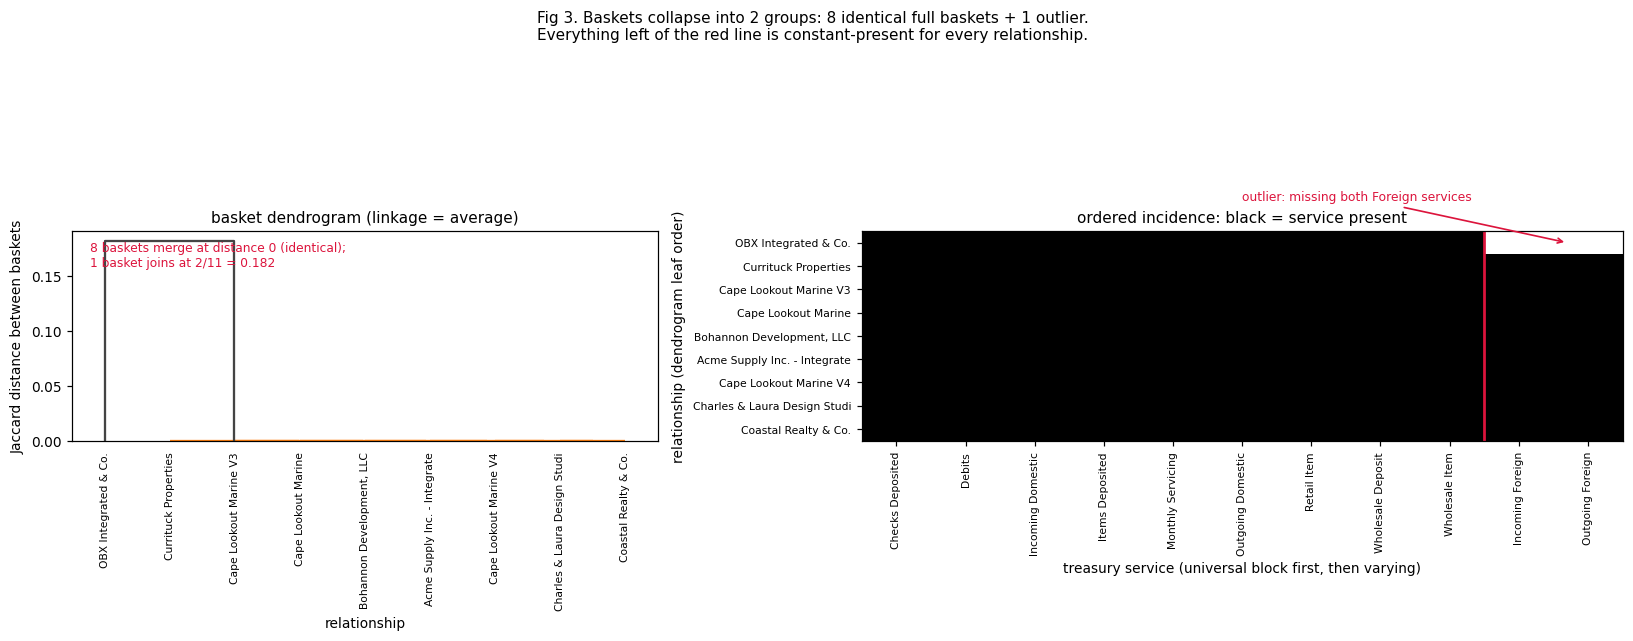

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 5.6),
                               gridspec_kw={"width_ratios": [1, 1.3]})

dnb = hierarchy.dendrogram(Zb, labels=basket_labels, ax=ax1, leaf_rotation=90,
                           color_threshold=0.05, above_threshold_color="#444444")
ax1.set_title(f"basket dendrogram (linkage = {LINKAGE_METHODS[0]})")
ax1.set_xlabel("relationship")
ax1.set_ylabel("Jaccard distance between baskets")
ax1.tick_params(axis="x", labelsize=7)
ax1.text(0.03, 0.95, "8 baskets merge at distance 0 (identical);\n"
                     "1 basket joins at 2/11 = 0.182",
         transform=ax1.transAxes, fontsize=8, color="crimson", va="top")

order = [basket_labels.index(l) for l in dnb["ivl"]]
col_order = [items.index(c) for c in UNIVERSAL + VARYING]
raw = M.to_numpy(dtype=int)
img = raw[np.ix_(order, col_order)]
ax2.imshow(img, cmap="Greys", vmin=0, vmax=1, aspect="auto")
ax2.set_xticks(range(n_i))
ax2.set_xticklabels([items[c] for c in col_order], rotation=90, fontsize=7)
ax2.set_yticks(range(len(order)))
ax2.set_yticklabels([basket_labels[i] for i in order], fontsize=7)
ax2.set_xlabel("treasury service (universal block first, then varying)")
ax2.set_ylabel("relationship (dendrogram leaf order)")
ax2.set_title("ordered incidence: black = service present")
ax2.axvline(len(UNIVERSAL) - 0.5, color="crimson", lw=1.8)
for yy, ii in enumerate(order):
    if raw[ii].sum() < n_i:
        ax2.annotate("outlier: missing both Foreign services",
                     xy=(n_i - 1.3, yy), xytext=(n_i - 6.0, yy - 1.8),
                     fontsize=8, color="crimson",
                     arrowprops=dict(arrowstyle="->", color="crimson", lw=1.1))

fig.suptitle("Fig 3. Baskets collapse into 2 groups: 8 identical full baskets + 1 "
             "outlier.\nEverything left of the red line is constant-present for "
             "every relationship.", fontsize=10, y=1.03)
plt.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

## Figure 4 — classical MDS projection of items

Classical (Torgerson) MDS on the Jaccard distance matrix, hand-rolled with
`numpy` double-centering plus an eigendecomposition — no new dependencies.
Because the 9 universal items are at mutual distance 0 they land on **one
coincident point**; a small deterministic jitter is applied *for label
legibility only* and is annotated as such on the figure. The embedding is
effectively rank 1.

positive eigenvalues: [0.020202 0.       0.       0.       0.       0.       0.       0.
 0.       0.       0.      ]
variance captured by 2 dimensions: 1.0000
effective rank (eigenvalues > 1e-9): 1


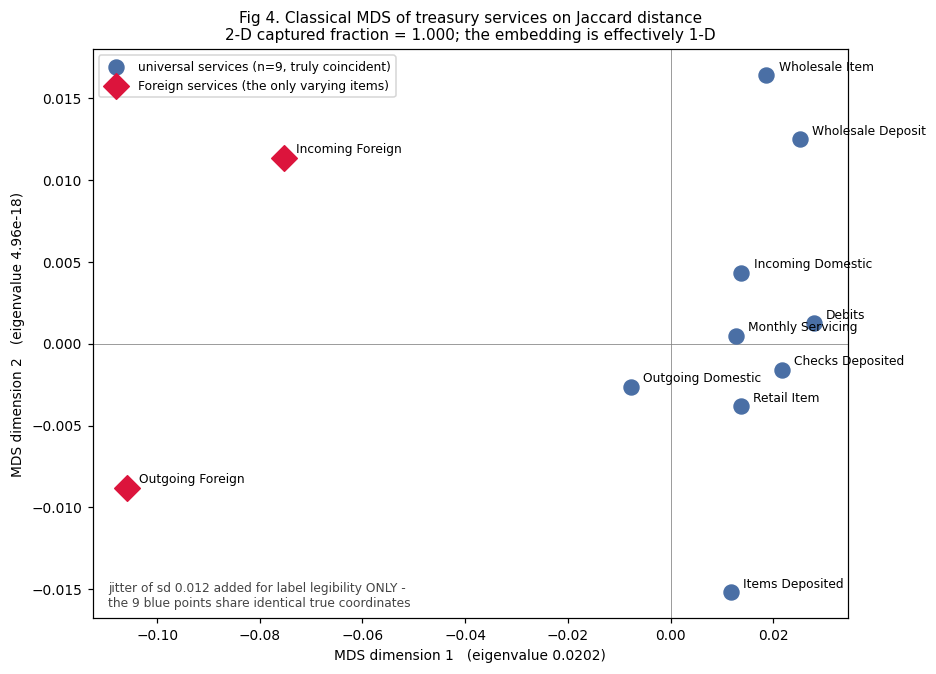

In [11]:
def classical_mds(dist: np.ndarray, k: int = 2):
    """Torgerson classical MDS. Returns (coords, explained_fraction, eigenvalues)."""
    n = dist.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    Bm = -0.5 * J @ (dist ** 2) @ J
    w, Vv = np.linalg.eigh(Bm)
    idx = np.argsort(w)[::-1]
    w, Vv = w[idx], Vv[:, idx]
    pos = np.clip(w, 0.0, None)
    coords = Vv[:, :k] * np.sqrt(pos[:k])
    frac = float(pos[:k].sum() / pos.sum()) if pos.sum() > 0 else 0.0
    return coords, frac, pos


XY, frac, eig = classical_mds(Jd, 2)
print("positive eigenvalues:", np.round(eig, 6))
print(f"variance captured by 2 dimensions: {frac:.4f}")
print("effective rank (eigenvalues > 1e-9):", int((eig > 1e-9).sum()))

rng = np.random.default_rng(0)
XYp = XY + rng.normal(0.0, 0.012, XY.shape)

fig, ax = plt.subplots(figsize=(8.6, 6.2))
is_u = np.array([it in UNIVERSAL for it in items])
ax.scatter(XYp[is_u, 0], XYp[is_u, 1], s=95, c="#4a6fa5",
           label=f"universal services (n={int(is_u.sum())}, truly coincident)", zorder=3)
ax.scatter(XYp[~is_u, 0], XYp[~is_u, 1], s=140, c="crimson", marker="D",
           label="Foreign services (the only varying items)", zorder=3)
for (x, y), lab in zip(XYp, items):
    ax.annotate(lab, (x, y), textcoords="offset points", xytext=(8, 3), fontsize=8)
ax.set_xlabel(f"MDS dimension 1   (eigenvalue {eig[0]:.4f})")
ax.set_ylabel(f"MDS dimension 2   (eigenvalue {eig[1]:.3g})")
ax.set_title("Fig 4. Classical MDS of treasury services on Jaccard distance\n"
             f"2-D captured fraction = {frac:.3f}; the embedding is effectively 1-D")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.legend(loc="upper left", fontsize=8)
ax.text(0.02, 0.02,
        "jitter of sd 0.012 added for label legibility ONLY -\n"
        "the 9 blue points share identical true coordinates",
        transform=ax.transAxes, fontsize=8, color="#444444")
plt.tight_layout()
plt.show()

---

## Conclusions

### What this analysis actually found

1. **Two distinct basket signatures across 9 relationships.** Eight
   relationships hold all 11 services; `OBX Integrated & Co.` holds 9, missing
   both Foreign services. Basket clustering recovers exactly this 8 + 1 split
   and nothing more.
2. **One genuine item relationship:** `Incoming Foreign` <-> `Outgoing Foreign`
   co-occur perfectly (8/8) and are the only pair with a defined, non-zero phi
   (= 1.0). With n = 9 and a single discordant basket this is *not*
   statistically significant; it is a description of nine rows.
3. **Nine mutually indistinguishable services.** Their columns are identical, so
   no distance, similarity, projection, or linkage can separate them. The
   dendrogram branches among them are tie-breaking artifacts — every one of
   those merges happens at height 0, as the printed merge heights confirm.

### Which measures I would trust at scale, and why

- **phi / MCC — trust first.** The only one of the six that is variance-aware:
  a constant item yields a zero denominator and phi declines to answer rather
  than reporting spurious perfect similarity. Chance-corrected, symmetric, and
  *signed* — it can express negative association, which none of the others can
  — and it is the normalised chi-square statistic, so it carries a ready
  significance interpretation once n is adequate.
- **Jaccard — trust with a support filter.** Well-behaved and interpretable
  *provided* near-universal and near-absent items are screened out first. It
  ignores `d`, which is usually right for sparse baskets but catastrophic here.
- **Cosine / Ochiai — redundant with each other** (shown numerically identical
  on binary data) and, like Jaccard, inflated by universal presence. Keep one.
- **Dice — drop.** Monotone in Jaccard, so it never reorders pairs; it adds a
  column and no information.
- **Sokal-Michener — avoid for basket work.** Crediting joint absence makes two
  rarely-sold services look similar purely because most customers buy neither.
  In a wide catalogue it converges toward 1.0 for nearly everything.

In practice: screen items to roughly `0.05 < support < 0.95`, rank with phi,
interpret with Jaccard, and require a basket count large enough that a
one-basket change does not move support materially.

### What is NOT concludable from this snapshot

- **No service affinities.** Nine services are constant; "X goes with Y" is
  unsupported for any pair involving them.
- **No customer segments.** There are 9 baskets and 2 signatures. The 8-basket
  cluster is defined by having everything, which is not a behavioural segment.
  We therefore assign it no name.
- **No cross-sell or whitespace opportunity**, beyond the arithmetic observation
  that one relationship lacks two services. Whether that is a sales gap, a
  product-eligibility rule, or a data-pipeline omission cannot be determined
  from this table.
- **No statistical significance.** At n = 9 support is quantised to ninths, and
  the single 9-vs-8 split cannot reach p < 0.05.
- **No validated group-level structure.** `TREASURY_SERVICE_GROUP_NAME` is 100%
  NULL in the fact table and must be recovered from a dimension in
  `INTEGRATION_TESTING`; that mapping is provisional, and at group grain all 3
  groups appear in all 9 baskets, so the matrix is fully constant.

The deliverable here is the **method** — six comparable measures, an explicit
zero-variance guard, two-linkage artifact detection, a basket-side collapse
check, and a dependency-free MDS — not a finding about this nine-relationship
snapshot.